## MIE360 Fall 2026 Project: Hospital Modeling and Simulation
### Deliverable 3.1: Input Modeling

Signatures
|Student|ID|
|-------|--|
|Gabriel Faustino|1011376823|
|Sunny Wu|1010978239|
|Benjamin Zhou|1011085772|

**Note: It is recommended to use a virtual environment (venv) before installing the required modules.** Run `python -m venv .venv` and `./.venv/Scripts/activate` before installing the required modules.

**Note: this notebook is designed to run with the locally-installed CSV data files after cloning.** Run `pip install -r ./deps/requirements.txt` before running.

In [2]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

### Visualizing and modeling arrival times

In [3]:
# Read arrivals data. Use the Day# column (idx 0) as the index.
df_arrivals = pd.read_csv("./data/Data_Arrivals.csv", index_col=0)
display(df_arrivals.head(5))
display(df_arrivals.shape)

,1am,2am,3am,4am,5am,6am,7am,8am,9am,10am,...,3pm,4pm,5pm,6pm,7pm,8pm,9pm,10pm,11pm,12am
Day1,0,0,2,1,0,0,0,2,1,4,...,3,2,1,7,4,5,2,3,4,2
Day2,3,2,1,0,0,0,0,0,3,1,...,3,4,6,6,2,2,3,2,3,3
Day3,1,0,2,1,0,1,1,2,3,0,...,4,5,8,7,4,3,1,2,2,4
Day4,1,0,0,1,0,2,0,5,2,2,...,4,2,3,8,4,8,3,3,3,5
Day5,1,2,0,1,1,1,2,1,1,1,...,8,2,10,5,6,2,3,3,4,3


(100, 24)

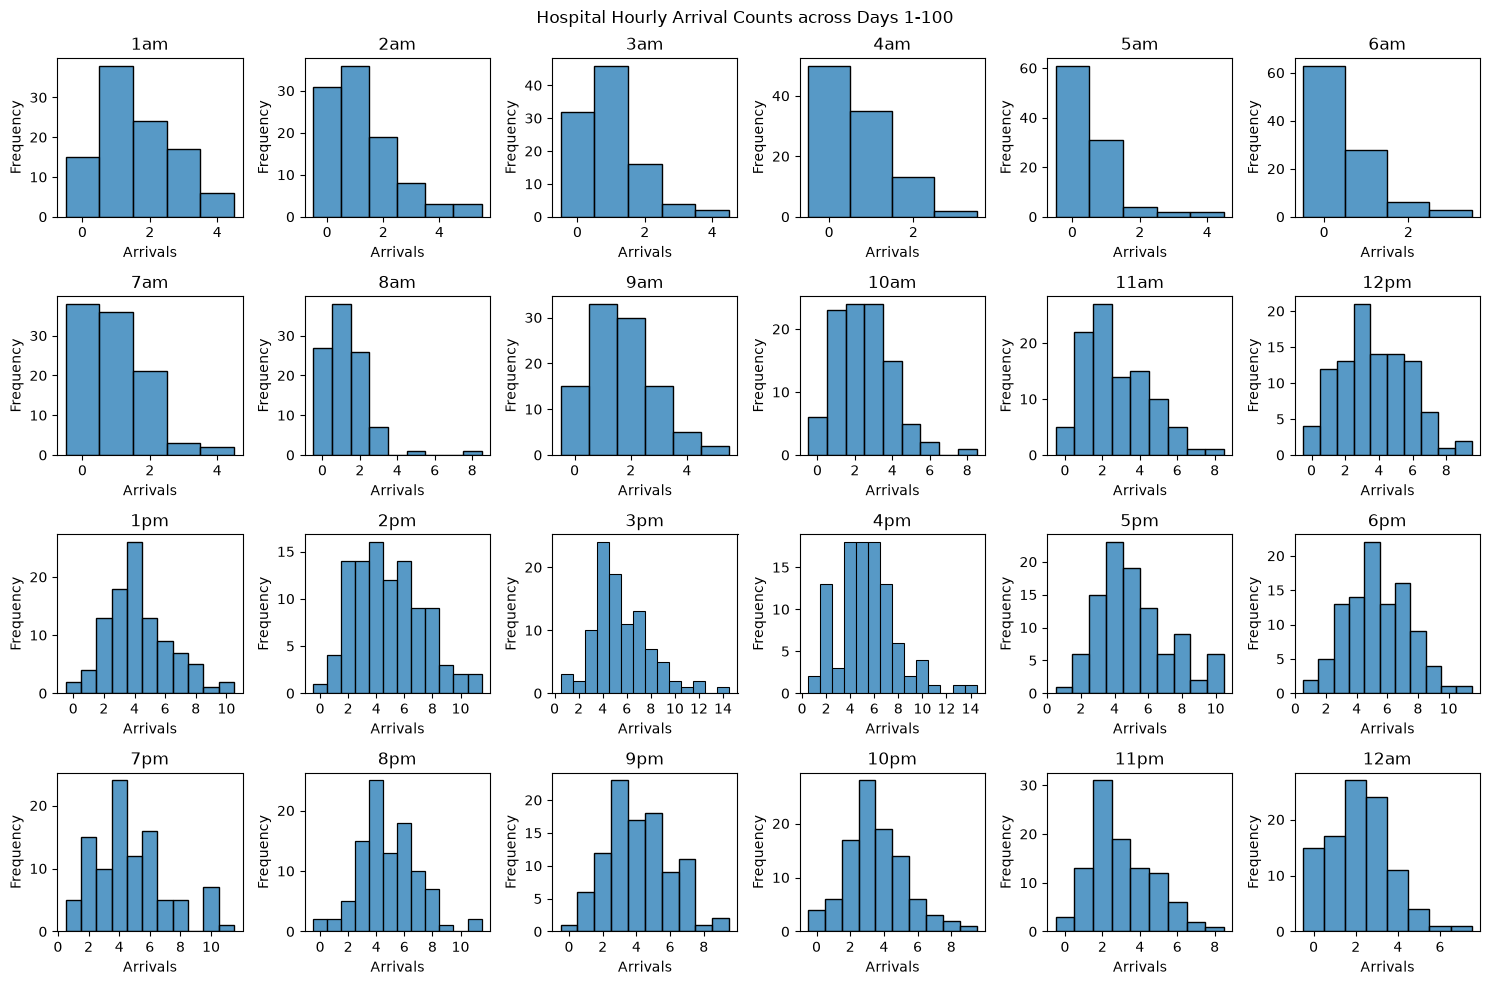

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Hospital Hourly Arrival Counts across Days 1-100")

axes = axes.flat
for i, col_name in enumerate(df_arrivals.columns):
    ax = axes[i]
    x = df_arrivals[col_name]
    sns.histplot(data=x, discrete=True, ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, x.max() + 1, 2))

plt.tight_layout()
plt.show()

Visual observation of the data suggests that 24 independent Poisson distributions are a likely fit for each hour, since:
1. it seems reasonable to assume that arriving hospital cases are independent, and
2. the data appears to exhibit right skew, which Poisson exhibits.

both of which are good reasons to try fitting all arrival distributions with Poisson distributions, which are often used to model independent arrivals.

In [5]:
# Calculate Poisson MLEs (sample mean) for each hour
poisson_mles = df_arrivals.sum(axis=0)/df_arrivals.shape[0]
poisson_mles.name = "lambda"
poisson_mles.to_csv("./out/arrival_poisson_fits.csv", index_label="hour")
display(poisson_mles)

1am     1.61
2am     1.25
3am     0.98
4am     0.67
5am     0.53
6am     0.49
7am     0.95
8am     1.24
9am     1.68
10am    2.48
11am    2.73
12pm    3.73
1pm     4.25
2pm     4.86
3pm     5.55
4pm     5.42
5pm     5.15
6pm     5.36
7pm     4.73
8pm     4.87
9pm     4.14
10pm    3.52
11pm    3.02
12am    2.20
Name: lambda, dtype: float64

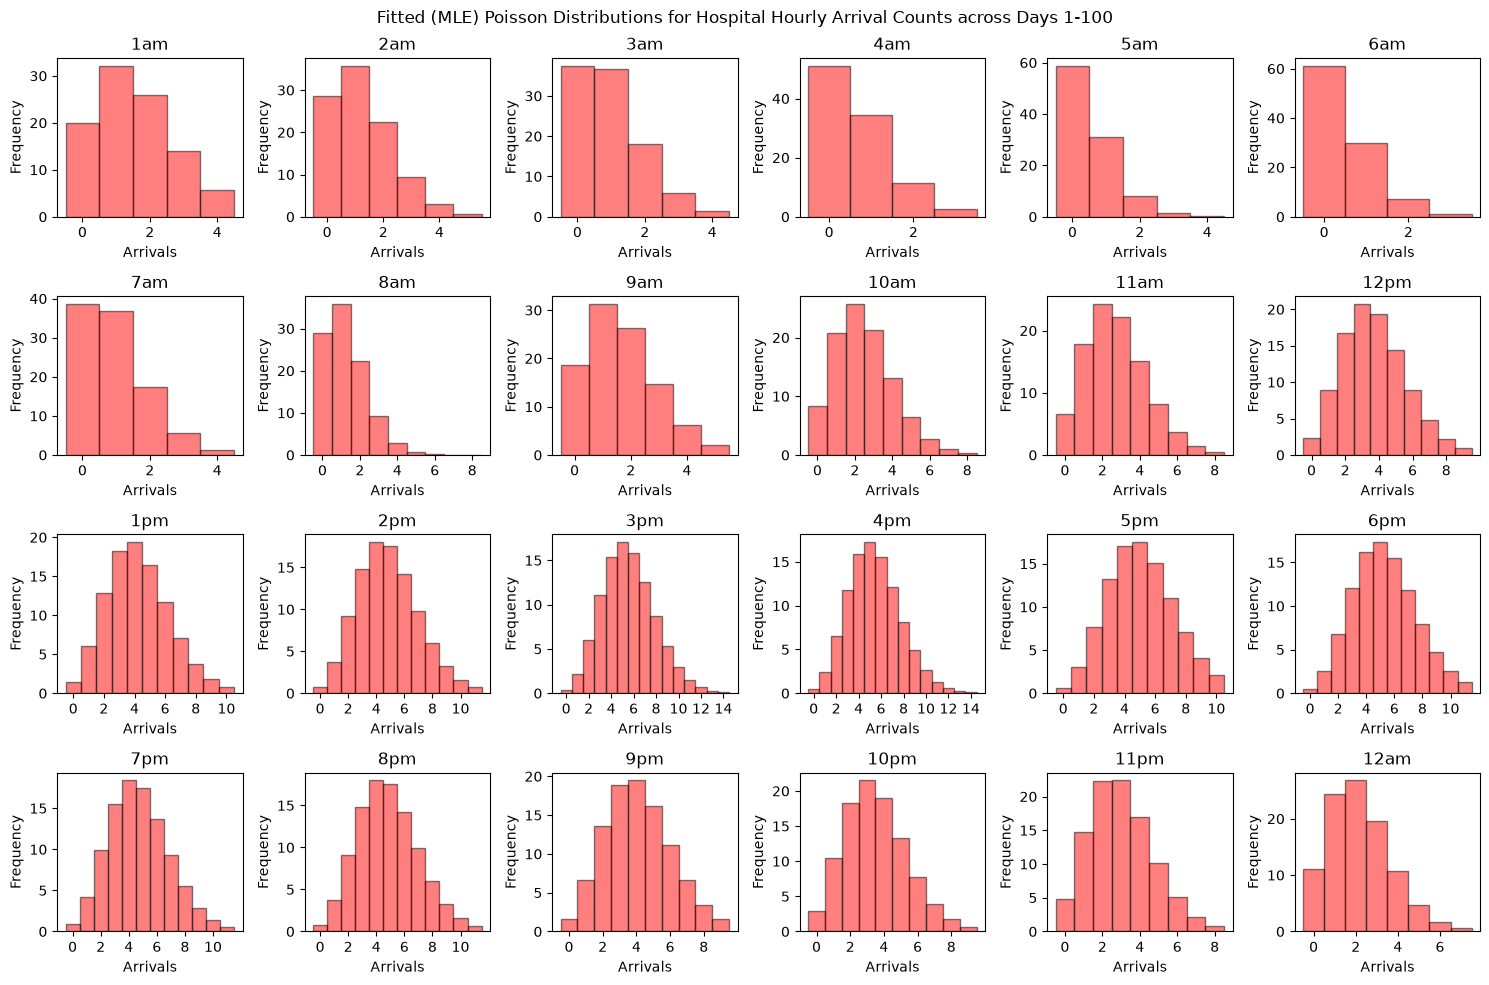

In [6]:
# Display scaled poisson distribution over visualization to quickly confirm if poisson is a good fit for modeling.
poisson_distributions = [stats.poisson(mu=rate) for rate in poisson_mles]

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Fitted (MLE) Poisson Distributions for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):
    x = np.arange(0, df_arrivals[col_name].max() + 1) # bins
    ax.bar(x, poisson_dist.pmf(x) * 100, color="red", alpha=0.5, edgecolor='black', width=1.0)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

fig.tight_layout()

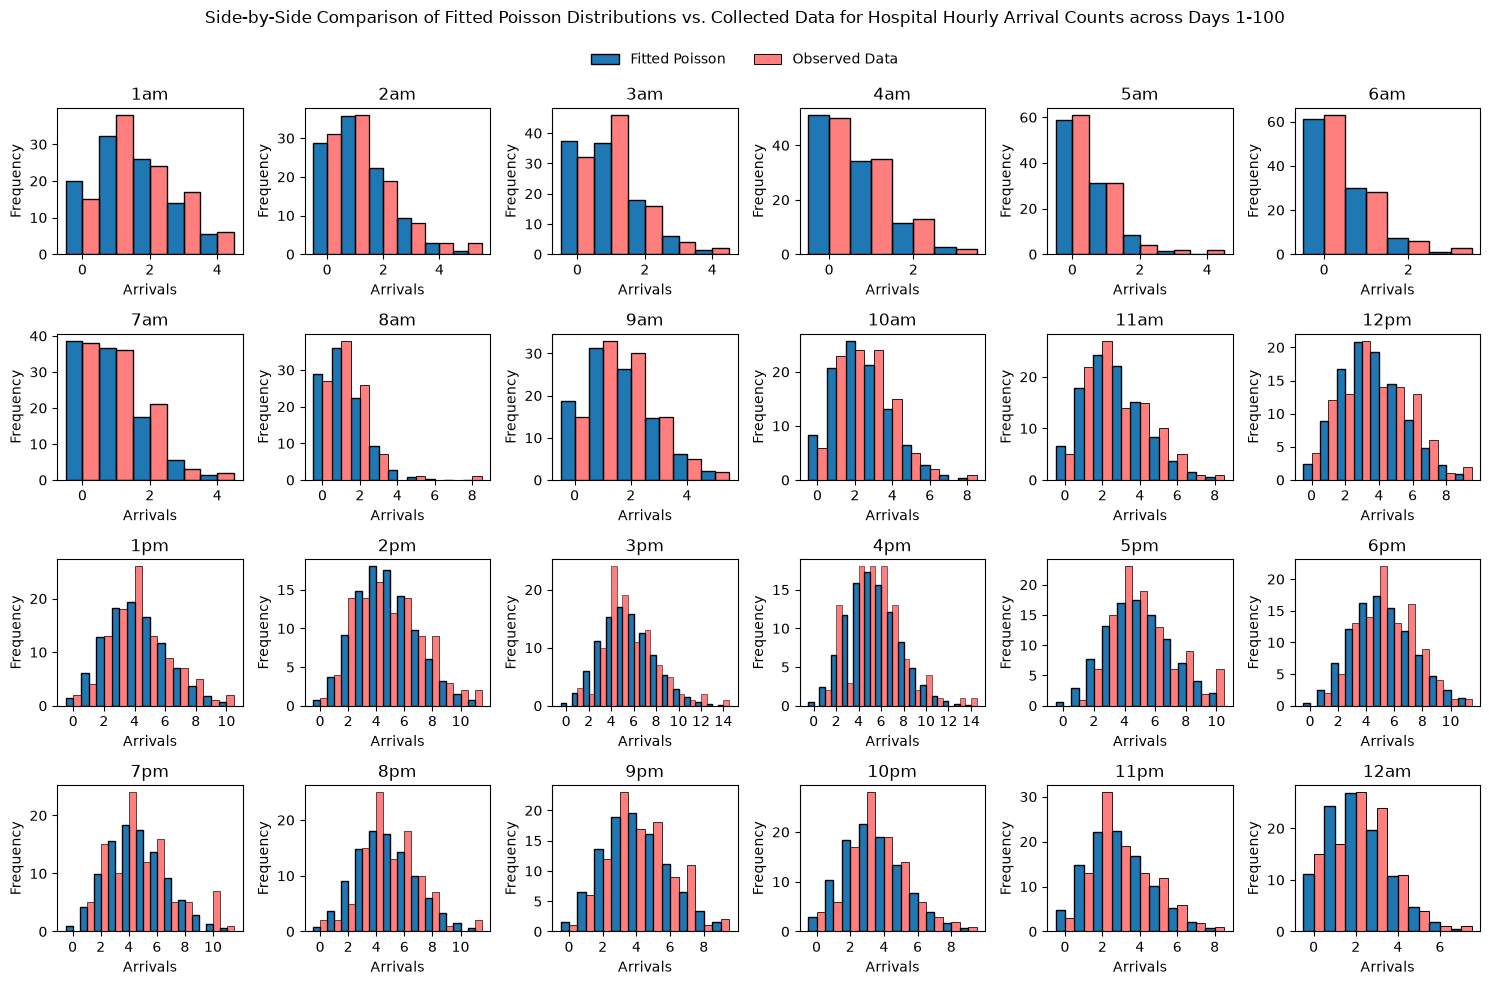

In [21]:
# Display the fitted Poisson distributions over the histograms of the actual data

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Side-by-Side Comparison of Fitted Poisson Distributions vs. Collected Data for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):

    # Plot poisson
    x1 = np.arange(0, df_arrivals[col_name].max() + 1) # number of possible arrivals in a specific hour
    ax.bar(x1 - 0.25, poisson_dist.pmf(x1) * 100, edgecolor='black', width=0.5, label="Fitted Poisson")

    # Plot histogram
    x2 = df_arrivals[col_name]
    sns.histplot(data=x2+0.25, discrete=True, ax=ax, color='red', alpha=0.5, shrink=0.5, label="Observed Data")

    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

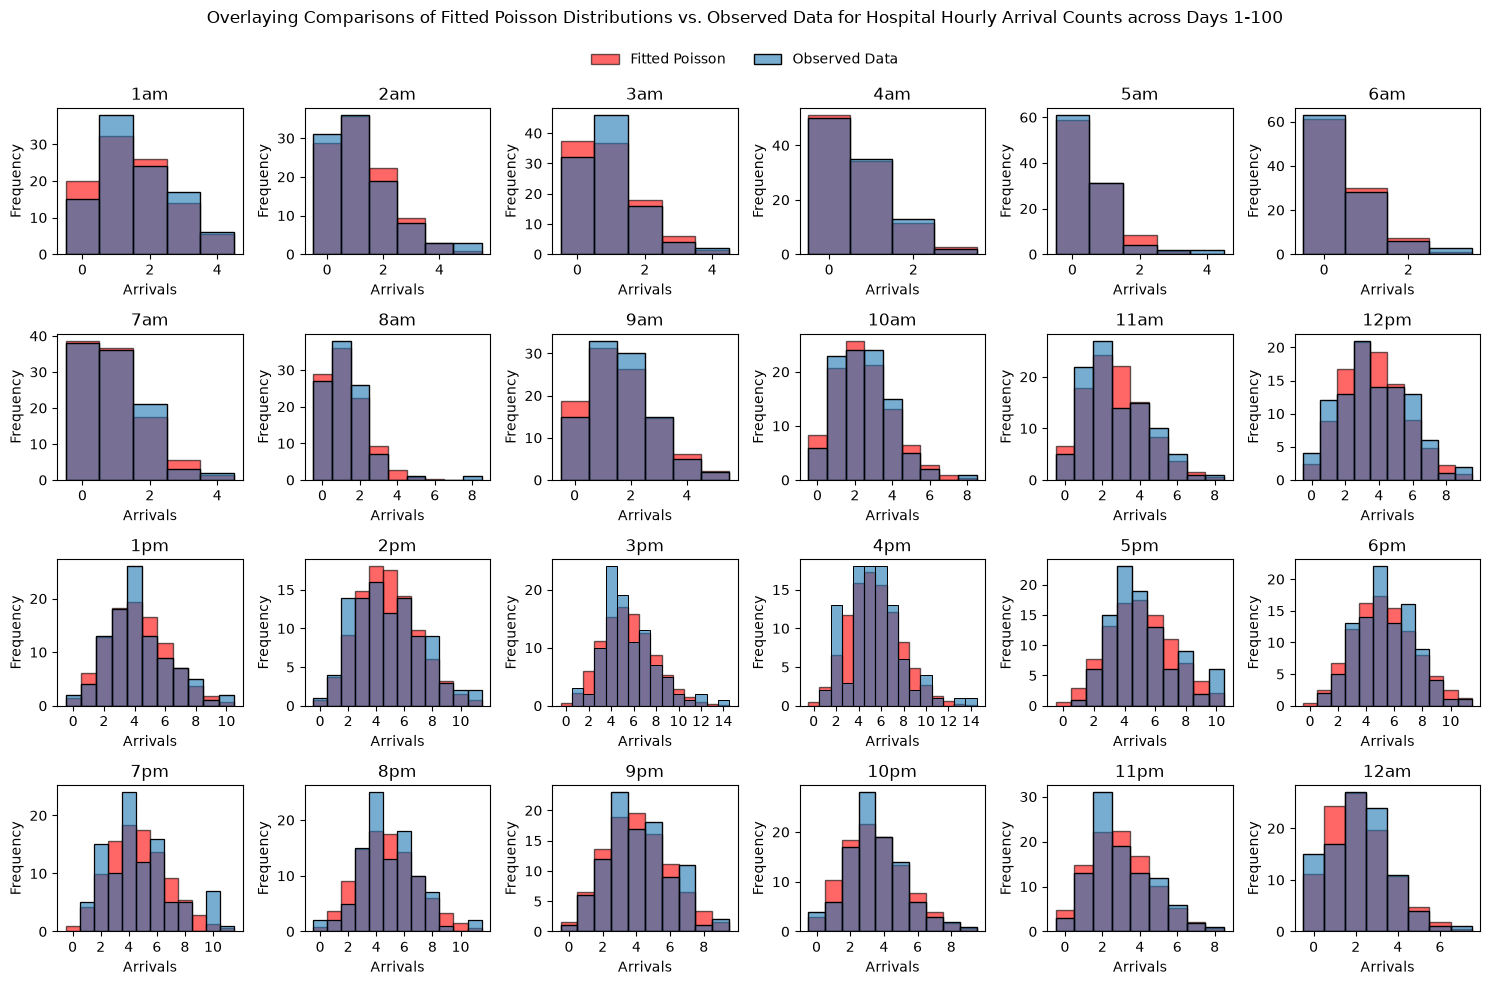

In [8]:
# Display the fitted Poisson distributions over the histograms of the actual data

n_days = len(df_arrivals)

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Overlaying Comparisons of Fitted Poisson Distributions vs. Observed Data for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):

    # Plot poisson
    x1 = np.arange(0, df_arrivals[col_name].max() + 1) # number of possible arrivals in a specific hour
    ax.bar(x1, poisson_dist.pmf(x1) * 100, color="red", alpha=0.6, edgecolor='black', width=1.0, label="Fitted Poisson")

    # Plot histogram
    x2 = df_arrivals[col_name]
    sns.histplot(data=x2, discrete=True, ax=ax, alpha=0.6, edgecolor='black', label="Observed Data")

    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [9]:
# Run chi-squared test of observed arrival counts versus proposed Poisson distribution
results = {}
for col_name, poisson_dist in zip(df_arrivals.columns, poisson_distributions):
    # Get observed counts
    observed_counts = df_arrivals[col_name].value_counts().sort_index()
    
    # Get expected counts from Poisson distribution
    x = np.arange(0, df_arrivals[col_name].max() + 1)
    expected_counts = poisson_dist.pmf(x) * observed_counts.sum()

    # add the tail probability to the last bin to last bin so that the expected counts sum to the total number of observations
    expected_counts[-1] += poisson_dist.sf(x[-1]) * observed_counts.sum() 
    
    # Align observed and expected counts by realigning the observed counts to the expected counts index
    observed_counts_aligned = observed_counts.reindex(x, fill_value=0)
    
    # Perform chi-squared test, ddof=1 to account for the estimated parameter (lambda)
    chi2_stat, p_value = stats.chisquare(f_obs=observed_counts_aligned, f_exp=expected_counts, ddof=1) 
    
    results[col_name] = {
        'chi2_stat': chi2_stat,
        'p_value': p_value,
        'observed_counts': observed_counts_aligned,
        'expected_counts': expected_counts,
        'distn': poisson_dist
    }

# 95% confidence level, so alpha = 0.05
alpha = 0.05
H_0_rejected_count = 0
p_values_rejected_by_hour = pd.DataFrame(columns=["p_value"])
rejected_distributions = {}

for col_name, result in results.items():
    if result['p_value'] < alpha:
        H_0_rejected_count += 1
        p_values_rejected_by_hour.loc[col_name] = [result["p_value"]]
        rejected_distributions[col_name] = result['distn']

percent_H_0_rejected = H_0_rejected_count / len(results) * 100

# Poisson distribution is a good fit in most cases. 
print(f"Percentage of hours where H_0 is rejected: {percent_H_0_rejected:.2f}%")
print(f"Hours where H_0 is rejected, with p-values:")
display(p_values_rejected_by_hour)

Percentage of hours where H_0 is rejected: 16.67%
Hours where H_0 is rejected, with p-values:


,p_value
5am,6.379222e-04
8am,1.748852e-43
4pm,2.223076e-02
7pm,4.351399e-05


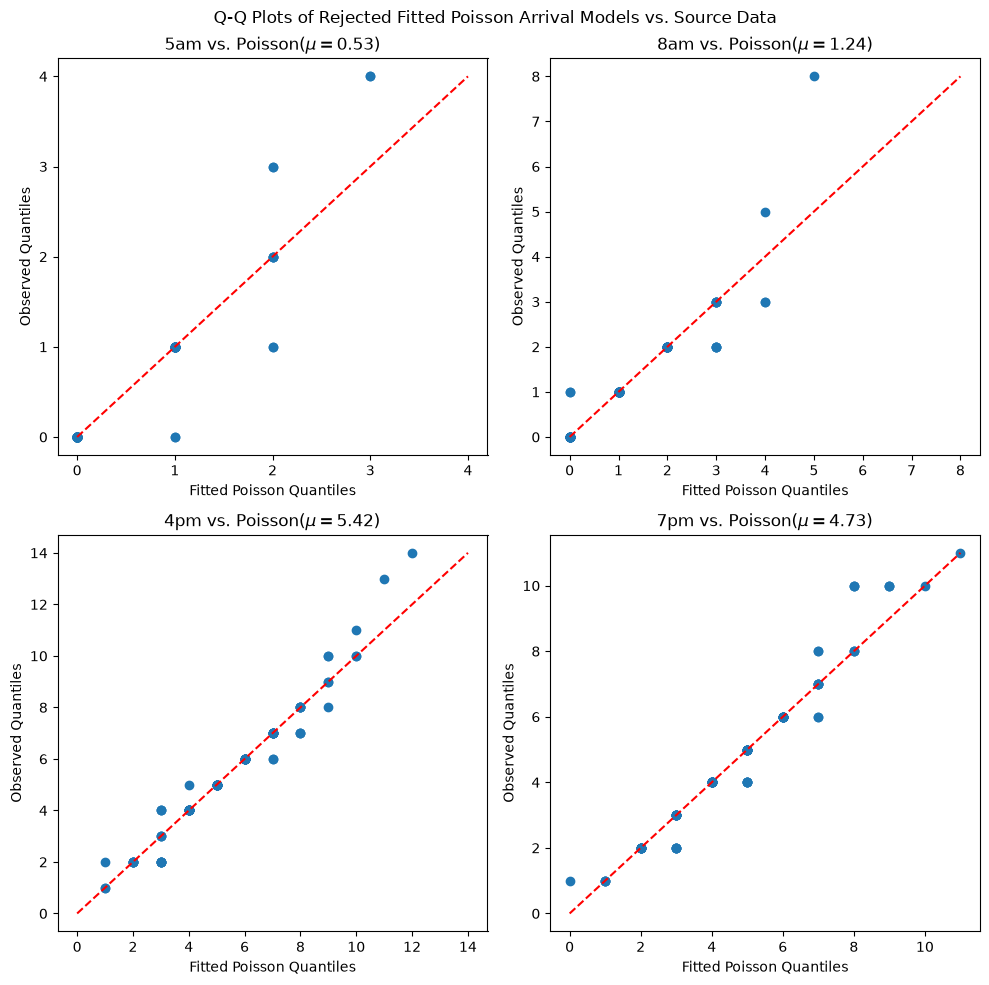

In [10]:
# Create Q-Q plots of the rejected hour Poisson distributions
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
fig.suptitle("Q-Q Plots of Rejected Fitted Poisson Arrival Models vs. Source Data")

for ax, (col_name, distn) in zip(axes.flat, rejected_distributions.items()):
    observed = df_arrivals[col_name]
    sorted_arrivals = np.sort(observed)
    n = observed.shape[0]
    probs = (np.arange(1, n + 1) - 0.5) / n
    fitted_poisson_quantiles = distn.ppf(probs)
    plot_max = max(fitted_poisson_quantiles.max(), observed.max())
    ax.scatter(fitted_poisson_quantiles, sorted_arrivals)
    ax.plot([0, plot_max], [0, plot_max], 'r--')
    ax.set_title(f"{col_name} vs. Poisson($\\mu={distn.mean()}$)")
    ax.set_xlabel('Fitted Poisson Quantiles')
    ax.set_ylabel('Observed Quantiles')
    ax.set_xticks(np.arange(0, plot_max + 1, 2 if plot_max >= 10 else 1))
    ax.set_yticks(np.arange(0, plot_max + 1, 2 if plot_max >= 10 else 1))

fig.tight_layout()
plt.show()

### Analysis of arrival modeling
Visually, the MLE Poisson distribution appears to largely fit most of the observed data, with a few histogram bins vastly differing. Our $\chi^2$ test conducted above largely agrees with this qualitative observation, showing that the MLE Poisson distribution is an acceptable fit for the majority (20/24) of the hours at the $\alpha=0.05$ confidence level.

We note that the $\chi^2$ test fails the following arrival periods at the $\alpha=0.05$ confidence level:
- 5 AM ($p=6.38\times10^{-4}$)
- 8 AM ($p=1.75\times10^{-43}$)
- 4 PM ($p=2.22\times10^{-2}$)
- 7 PM ($p=4.35\times10^{-5}$)

On visual inspection, the failing hours appear to be:
- noisy (4 PM and 7 PM), or
- have outliers that distort the test (5 AM, 8 PM, 7 PM).

Inspecting their corresponding Q-Q plots, the data for all 4 rejects largely follow the line in a staircase fashion. This is particularly evident at 4 PM and 7 PM, which have larger ranges (0-14 arrivals and 0-11 arrivals, respectively) and so the trend holds better with the presence of a few outliers, particularly near the higher observed arrival counts. On the other hand, the sparser Q-Q plots with smaller range for 5 AM and 8 AM are seen to be greatly affected by outliers, but still mostly follow the fitted line at lower counts.

Ultimately, we believe that, bar these discrepancies, an all-Poisson approach across all 24 hours is still appropriate for our input modeling.

### Visualizing and modeling service times

In [11]:
# Read treatment (service) time data. Use the ID column (idx 0) as the index.
df_treatment_raw = pd.read_csv("./data/Data_TreatmentTimes.csv", index_col=0)
df_treatment_raw = df_treatment_raw.rename(columns={"Treatment Time (Days)": "TreatmentTime"})
display(df_treatment_raw.head(5))
display(df_treatment_raw.shape)
print(df_treatment_raw["Specialty"].unique())

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
1,0.770322,Renal
2,1.911212,Card
3,4.199311,Respi
4,2.527663,Gastro_Endo


(18565, 2)

<ArrowStringArray>
['Ortho', 'Renal', 'Card', 'Respi', 'Gastro_Endo']
Length: 5, dtype: str


In [12]:
# Group treatment time data by specialty.
# We assume that the treatment time distribution for a given specialty is the same across all wards under that specialty.
# (We are not given information about service times in each ward.)
df_treatment_by_specialty = df_treatment_raw.groupby(["Specialty"])
display(df_treatment_by_specialty.describe())

TreatmentTime                                              \
                    count      mean       std           min       25%   
Specialty                                                               
Card               4321.0  2.884995  3.515021  5.928158e-02  0.926157   
Gastro_Endo        3254.0  3.375186  3.639022  6.806160e-04  0.815995   
Ortho              3425.0  5.490906  5.491733  3.238330e-04  1.549496   
Renal              3244.0  4.823262  6.828324  2.105476e-07  0.517170   
Respi              4321.0  3.296486  5.696918  4.035753e-02  0.782429   

                                             
                  50%       75%         max  
Specialty                                    
Card         1.774205  3.454252   42.392131  
Gastro_Endo  2.188181  4.703748   28.626801  
Ortho        3.861794  7.595541   52.501056  
Renal        2.228971  6.244268   59.849193  
Respi        1.747665  3.666749  143.763709

In [13]:
# Peek the grouping
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    display(group_name[0])
    display(df_group.head(5))

'Card'

,TreatmentTime,Specialty
ID,,
2,1.911212,Card
5,2.076513,Card
6,1.862886,Card
14,1.343026,Card
17,5.331829,Card


'Gastro_Endo'

,TreatmentTime,Specialty
ID,,
4,2.527663,Gastro_Endo
18,2.758086,Gastro_Endo
27,10.760506,Gastro_Endo
44,0.495989,Gastro_Endo
47,10.935222,Gastro_Endo


'Ortho'

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
15,0.653278,Ortho
20,1.716359,Ortho
24,0.549169,Ortho
25,9.000257,Ortho


'Renal'

,TreatmentTime,Specialty
ID,,
1,0.770322,Renal
7,0.001040,Renal
10,11.152471,Renal
11,3.017819,Renal
12,2.317516,Renal


'Respi'

,TreatmentTime,Specialty
ID,,
3,4.199311,Respi
8,0.213762,Respi
9,0.271861,Respi
13,1.609639,Respi
16,9.681560,Respi


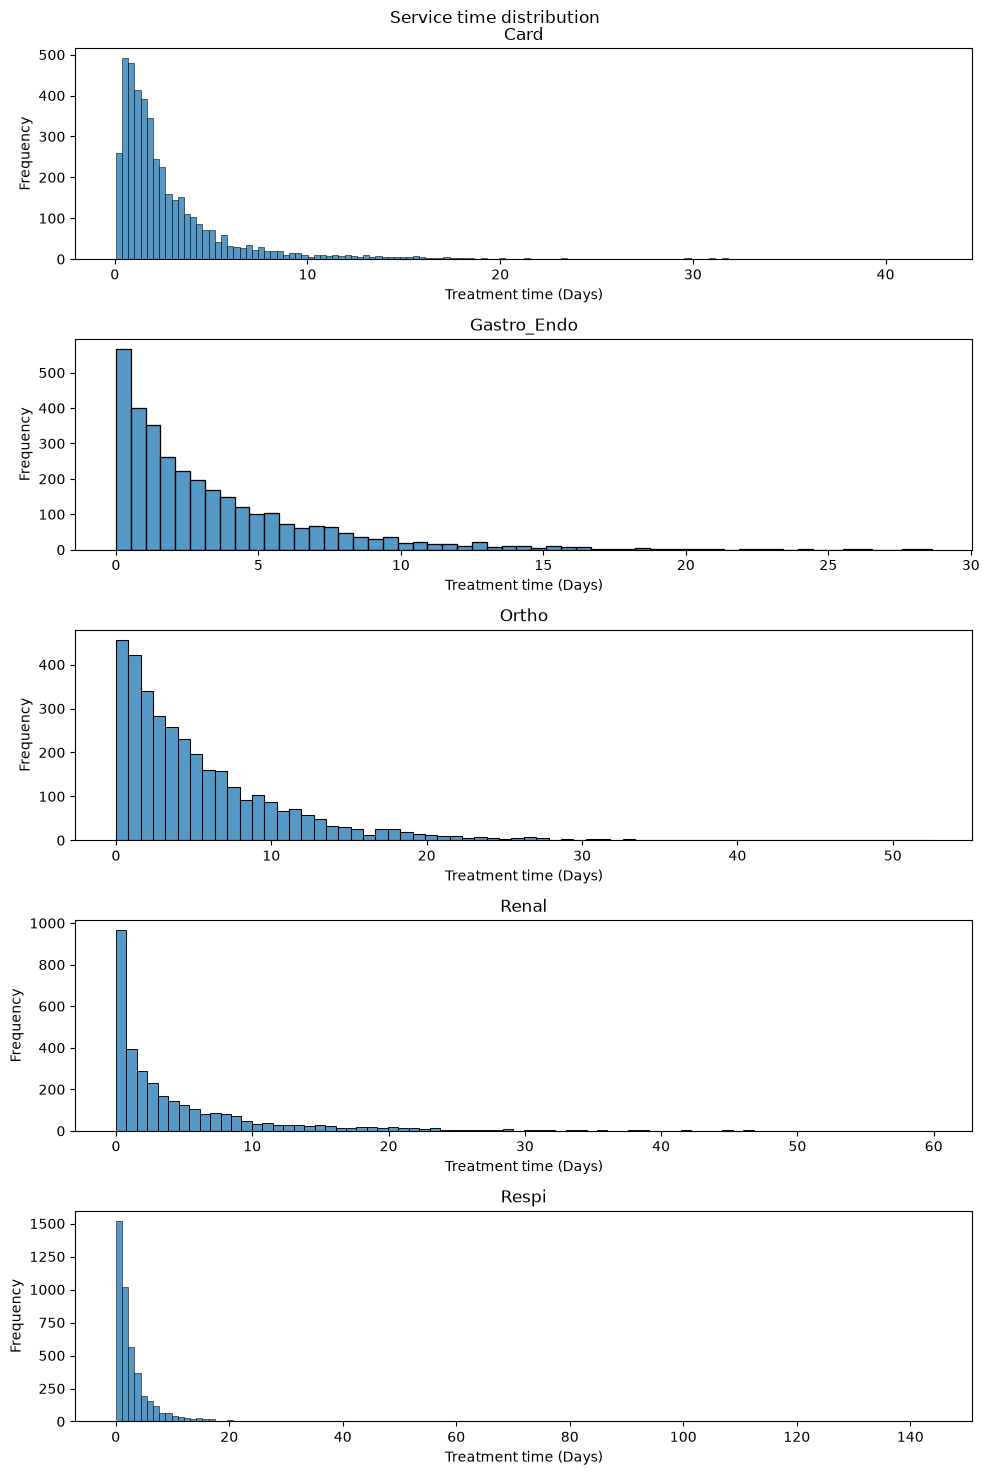

In [14]:
# Visualize treatment time data by speciality in histograms. (Preliminary.)
fig, axes = plt.subplots(5, 1, figsize=(10, 15))
fig.suptitle("Service time distribution")

for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    ax = axes.flat[i]
    sns.histplot(data=df_group["TreatmentTime"], ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Treatment time (Days)")
    ax.set_title(group_name[0])

for ax in axes.flat[i+1:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Compare gamma, exponential, and lognormal distributions

Visually observing the above preliminary histograms, we note that the specialities without a specified treatment time distribution (Cardiology, Gastroenterology-Endocrine, Orthopedic, Renal Disease, and Respiratory) mostly follow a power law-like distribution, with the Cardiology histogram exhibiting a dip left to the modal bin. Therefore, we guess that each of the remaining specialities can be best modeled by one of the following distributions:
- Gamma,
- Exponential, or
- Lognormal

In [15]:
# MLEs for gamma distribution
gamma_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit gamma distribution to the treatment time data for this specialty
    shape, loc, scale = stats.gamma.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    gamma_mles[group_name[0]] = (shape, loc, scale)

# MLEs for exponential distribution
exponential_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit exponential distribution to the treatment time data for this specialty
    loc, scale = stats.expon.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    exponential_mles[group_name[0]] = (loc, scale)

# MLEs for lognormal distribution
lognormal_mles = {}
for group_name, df_group in df_treatment_by_specialty:  
    # Fit lognormal distribution to the treatment time data for this specialty
    shape, loc, scale = stats.lognorm.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    lognormal_mles[group_name[0]] = (shape, loc, scale)

gamma_mles


{'Card': (1.1705418104963468, 0, np.float64(2.464666143204533)),
 'Gastro_Endo': (0.8466957605437156, 0, np.float64(3.9863037301331734)),
 'Ortho': (1.0147367271709278, 0, np.float64(5.411163405986773)),
 'Renal': (0.5121985074122511, 0, np.float64(9.416782989343686)),
 'Respi': (0.8973004097766168, 0, np.float64(3.6737819516631847))}

In [16]:
# Chi-squared test for goodness of fit for each distribution and each specialty
# e.g., Orthopedic and lognormal, orthopedic and gamma, orthopedic and exponential, etc.

gamma_results = {}
exponential_results = {}
lognormal_results = {}

# Integers represent ddof: 2 parameters being estimated for gamma and lognormal, 1 parameter for exponential
models = [("Gamma", stats.gamma, gamma_mles, 2, gamma_results),
          ("Exponential", stats.expon, exponential_mles, 1, exponential_results),
          ("Lognormal", stats.lognorm, lognormal_mles, 2, lognormal_results)]

for group_name, df_group in df_treatment_by_specialty:
    specialty = group_name[0] 
    times = df_group["TreatmentTime"]
    n = len(times) # Number of observations for this specialty

    # Obtain appropriate bin number. Use up to 10 bins with at least 5 expected observations each.
    n_bins = max(1, min(10, n // 5))

    # Quantiles of the fitted distribution will be used to create bins for the chi-squared test.
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]

    for _, distribution, mles, ddof, results in models:
        # extract MLEs for the current specialty and fit the distribution
        fitted_dist = distribution(*mles[specialty]) 

        bin_edges = np.r_[-np.inf, fitted_dist.ppf(quantiles), np.inf]

        observed_counts, _ = np.histogram(times, bins=bin_edges)

        # difference in CDF values at bin edges gives the expected proportion of observations 
        # in each bin, multiplied by n gives expected counts
        expected_counts = n * np.diff(fitted_dist.cdf(bin_edges)) 
        chi2_stat, p_value = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts, ddof=ddof)

        # Store results for this specialty and distribution
        results[specialty] = {"chi2_stat": chi2_stat,
                              "p_value": p_value,
                              "observed_counts": observed_counts,
                              "expected_counts": expected_counts,
                              "bin_edges": bin_edges,
                              "mles": mles[specialty]}

good_fits = pd.DataFrame(columns=["p", "shape", "loc", "scale"]).rename_axis("distribution_specialty")
# Conclusions based on p-values
k = 0
for name, _, _, _, results in models:
    p_values = [result["p_value"] for result in results.values()]
    num_tested = sum(np.isfinite(p) for p in p_values)
    num_rejections = sum(p < 0.05 for p in p_values)

    # Find and append specialties that fit well to a distribution (p-value >= 0.05)
    for specialty, result in results.items():
        if result["p_value"] >= 0.05:
            mles = result["mles"]
            mle_shape = mles[0] if len(mles) == 3 else None
            mle_loc = mles[-2]
            mle_scale = mles[-1]
            good_fits.loc[f"{name}-{specialty}"] = [result["p_value"], mle_shape, mle_loc, mle_scale]
            k += 1

    print(f"At the 5% level, rejected the {name} fit for {num_rejections} of {num_tested} tested specialties.")

good_fits.to_csv("./out/treatment_distribution_fits.csv")
print("Table of distributions and specialities that pair well, with p-values and applicable MLEs:")
display(good_fits)

At the 5% level, rejected the Gamma fit for 2 of 5 tested specialties.
At the 5% level, rejected the Exponential fit for 4 of 5 tested specialties.
At the 5% level, rejected the Lognormal fit for 3 of 5 tested specialties.
Table of distributions and specialities that pair well, with p-values and applicable MLEs:


,p,shape,loc,scale
distribution_specialty,,,,
Gamma-Gastro_Endo,0.886080,0.846696,0.0,3.986304
Gamma-Ortho,0.321779,1.014737,0.0,5.411163
Gamma-Renal,0.674105,0.512199,0.0,9.416783
Exponential-Ortho,0.379521,NaN,0.0,5.490906
Lognormal-Card,0.175105,0.986174,0.0,1.777177
Lognormal-Respi,0.280705,1.133348,0.0,1.717883


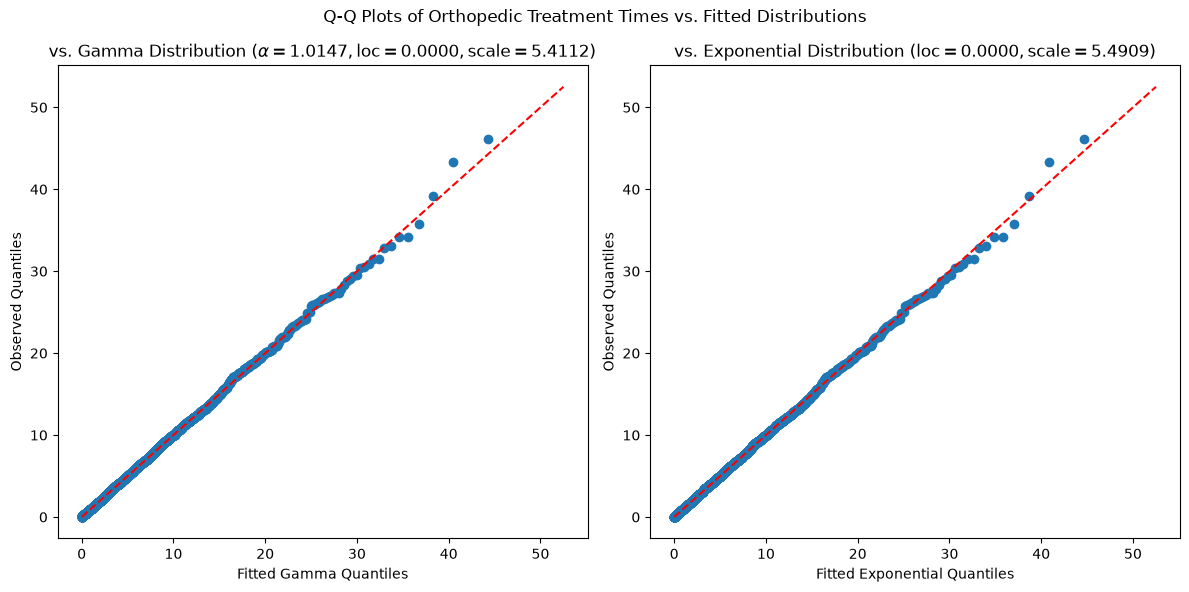

In [17]:
# Observing whether Exponential or Gamma distribution is better for Orthopedic treatment times using QQ plot

# fitted quantiles on x-axis, observed quantiles on y-axis
for specialty, df_group in df_treatment_by_specialty:

    # ("Ortho,") is returned when grouping by specialty, so we need to check if "Ortho" is in the tuple
    if "Ortho" in specialty:

        # Dictionaries expect "Ortho" for index
        specialty = "Ortho"
        times = df_group["TreatmentTime"]
        n = len(times)

        # Generate quantiles for the fitted distributions
        quantiles = np.linspace(0, 1, n)
        
        # Fit distributions
        gamma_params = gamma_mles[specialty]
        exponential_params = exponential_mles[specialty]
        fitted_gamma_quantiles = stats.gamma.ppf(quantiles, *gamma_params)
        fitted_exponential_quantiles = stats.expon.ppf(quantiles, *exponential_params)

        # Sort observed data for QQ plot
        sorted_times = np.sort(times)

        # Create Q-Q plots
        plt.figure(figsize=(12, 6))
        plt.suptitle("Q-Q Plots of Orthopedic Treatment Times vs. Fitted Distributions")

        # Gamma Q-Q plot
        plt.subplot(1, 2, 1)
        plt.scatter(fitted_gamma_quantiles, sorted_times)
        plt.plot([sorted_times.min(), sorted_times.max()], [sorted_times.min(), sorted_times.max()], 'r--')
        plt.title(f"vs. Gamma Distribution ($\\alpha={gamma_params[0]:0.4f},\\text{{loc}}={gamma_params[1]:0.4f},\\text{{scale}}={gamma_params[2]:0.4f}$)")
        plt.xlabel('Fitted Gamma Quantiles')
        plt.ylabel('Observed Quantiles')

        # Exponential Q-Q plot
        plt.subplot(1, 2, 2)
        plt.scatter(fitted_exponential_quantiles, sorted_times)
        plt.plot([sorted_times.min(), sorted_times.max()], [sorted_times.min(), sorted_times.max()], 'r--')
        plt.title(f"vs. Exponential Distribution ($\\text{{loc}}={exponential_params[0]:0.4f},\\text{{scale}}={exponential_params[1]:0.4f}$)")
        plt.xlabel('Fitted Exponential Quantiles')
        plt.ylabel('Observed Quantiles')

        plt.tight_layout()
        plt.show()

### Side-by-Side Comparison of distribution-specialty pairs

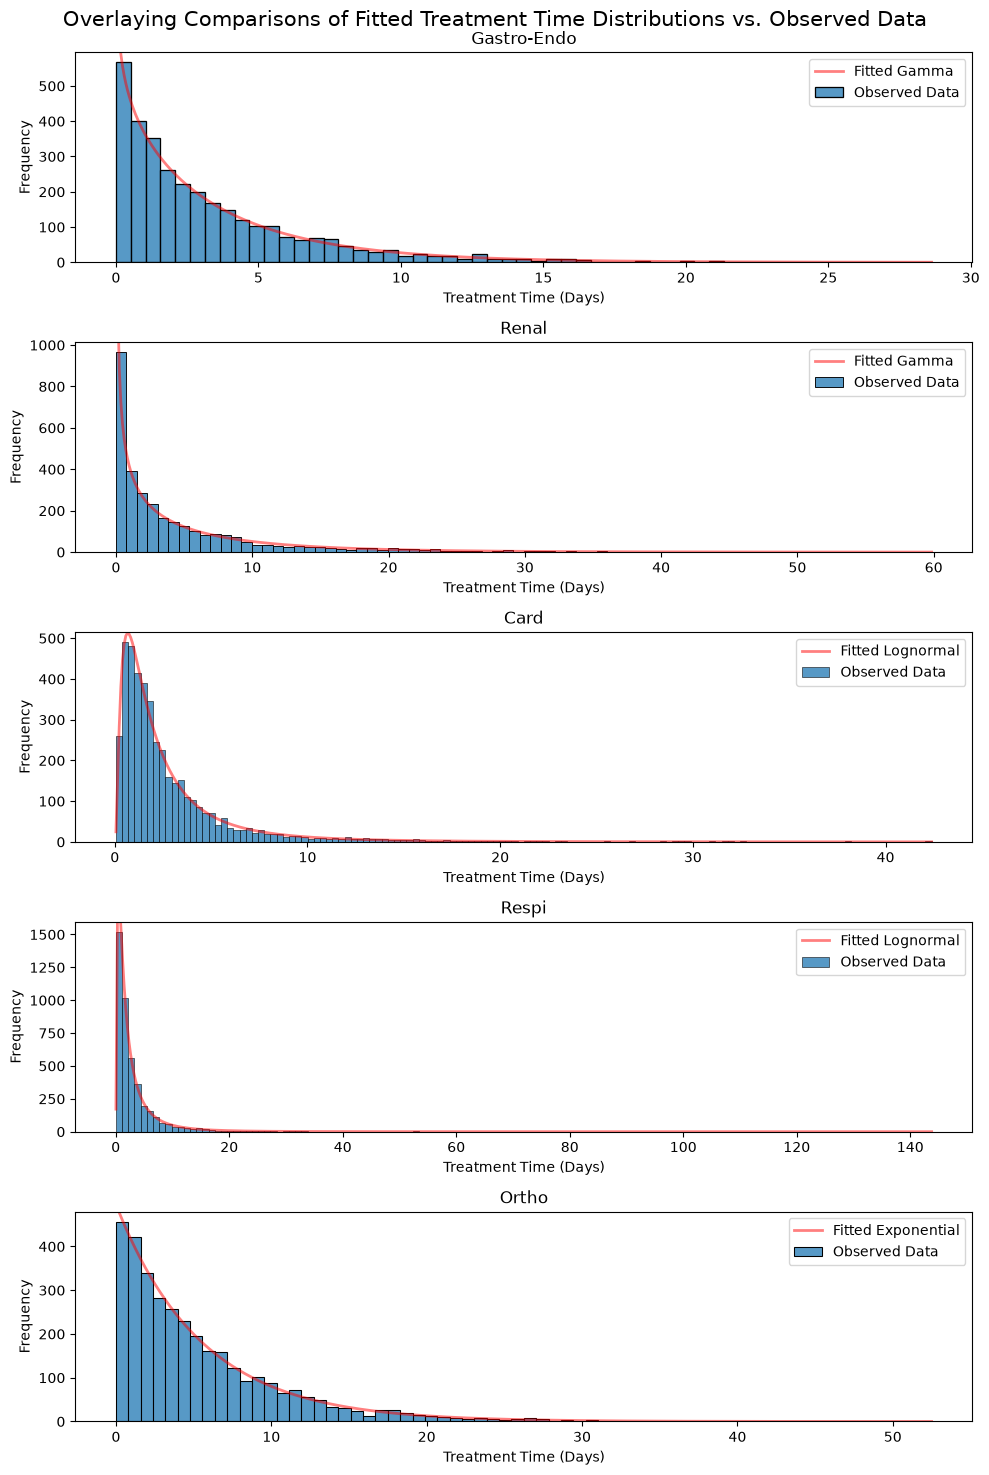

In [18]:
# Define treatment specialties and fitted distributions
comparisons = [
    ("Gastro_Endo", "Gamma", "Gamma-Gastro_Endo"),
    ("Renal", "Gamma", "Gamma-Renal"),
    ("Card", "Lognormal", "Lognormal-Card"),
    ("Respi", "Lognormal", "Lognormal-Respi"),
    ("Ortho", "Exponential", "Exponential-Ortho")
]

# Use the same grouped data as the original histograms
grouped_data = {(name[0] if isinstance(name, tuple) else name): df_group["TreatmentTime"].dropna() for name, df_group in df_treatment_by_specialty}

fig, axes = plt.subplots(5, 1, figsize=(10, 15))
fig.suptitle("Overlaying Comparisons of Fitted Treatment Time Distributions vs. Observed Data", fontsize=15)

for ax, (specialty, dist_type, mle_key) in zip(axes.flat, comparisons):

    # Get original treatment-time data and fitted MLE parameters
    data = grouped_data[specialty]
    params = good_fits.loc[mle_key]

    # Define fitted distributions
    if dist_type == "Gamma":
        fitted_dist = stats.gamma(a=params["shape"], loc=params["loc"], scale=params["scale"])
    elif dist_type == "Lognormal":
        fitted_dist = stats.lognorm(s=params["shape"], loc=params["loc"], scale=params["scale"])
    else:
        fitted_dist = stats.expon(loc=params["loc"], scale=params["scale"])

    # Plot original histogram
    bins = np.histogram_bin_edges(data, bins="auto")
    sns.histplot(data=data, bins=bins, stat="count", ax=ax, edgecolor="black", label="Observed Data")
    hist_ylim = ax.get_ylim() # for consistent scaling

    # Overlay fitted PDF scaled to histogram frequencies
    x = np.linspace(max(0.001, bins[0]), bins[-1], 500)
    bin_width = bins[1] - bins[0]
    ax.plot(x, fitted_dist.pdf(x) * len(data) * bin_width, color="red", alpha=0.5, linewidth=2, label=f"Fitted {dist_type}")
    ax.set_ylim(hist_ylim) # limit y to preserve scaling 

    ax.set_title("Gastro-Endo" if specialty == "Gastro_Endo" else specialty)
    ax.set_xlabel("Treatment Time (Days)")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

### Analysis of treatment modeling

Visually, the histograms suggest Gamma, Exponential, and Lognormal distributions as possible candidates to model the treatment (service) times for Cardiology, Renal Disease, Respiratory, Orthopedic and Gastroenterology-Endocrine specialties. 

After calculating the MLE parameters for each distribution and performing a $\chi^2$ goodness-of-fit test for each distribution-specialty pair, we observe at the $\alpha=0.05$ confidence level:
- The Gamma distribution is a good fit for the Gastro-Endo ($p=0.886$), Orthopedic ($p=0.322$), and Renal Disease ($p=0.674$) treatment times.
- The Exponential distribution is a good fit for the Orthopedic ($p=0.380$) treatment time.
- The Lognormal distribution is a good fit for the Cardiology ($p=0.175$) and Respiratory ($p=0.281$) treatment times.

The Q-Q plots for comparing Gamma and Exponential fits to Orthopedic treatment times show nearly identical agreement with the observed quantiles, including in the upper tail. Hence, we choose the Exponential distribution to approximate Orthopedic treatment times because it gives essentially the same fit with one fewer parameter, which can provide more stable predictions between different samples. For the remaining specialities, we will use the Gamma distribution for approximating Gastroenterology-Endocrine and Renal Disease treatment times, and the Lognormal distribution for approximating Cardiology and Respiratory treatment times.
